# Activity 8.02: Visualizing City Density by the First Letter

Student ID: MC66089

The file in this folder is `world_cities_pop.csv`. It has no continent column, so European cities are selected with country codes. The displayed name is `AccentCity`. Press a letter in `geoplotlib.show()` to change the filter. The figures below are the saved views for every city, then Z, A, B and C.


In [1]:
import io
import os
import urllib.request

import pandas as pd
import geoplotlib
from PIL import Image as PILImage
from geoplotlib.core import BatchPainter, GeoplotlibApp, MapLayer
from geoplotlib.layers import BaseLayer
from geoplotlib.utils import BoundingBox
from IPython.display import Image, display

EUROPE = {
    'ad', 'al', 'at', 'ba', 'be', 'bg', 'by', 'ch', 'cy', 'cz', 'de', 'dk',
    'ee', 'es', 'fi', 'fr', 'gb', 'gi', 'gr', 'hr', 'hu', 'ie', 'is', 'it',
    'li', 'lt', 'lu', 'lv', 'mc', 'md', 'me', 'mk', 'mt', 'nl', 'no', 'pl',
    'pt', 'ro', 'rs', 'se', 'si', 'sk', 'sm', 'ua', 'va',
}
EUROPE_BBOX = BoundingBox(north=71, south=34, west=-25, east=45)

_orig_get_tile = MapLayer.get_tile


def _get_tile_sync(self, zoom, xtile, ytile):
    if xtile < 0 or ytile < 0 or xtile >= 2 ** zoom or ytile >= 2 ** zoom:
        return None
    url = self.url_generator(zoom, xtile, ytile)
    dir_path = os.path.expanduser('~') + '/geoplotlib_tiles/%s/%d/%d/' % (self.tiles_dir, zoom, xtile)
    download_path = dir_path + '%d.png' % ytile
    os.makedirs(dir_path, exist_ok=True)
    if not os.path.isfile(download_path):
        req = urllib.request.Request(url, headers={'User-Agent': 'CISC7204-Activity802/1.0'})
        try:
            with urllib.request.urlopen(req, timeout=30) as source:
                content = source.read()
            if content.startswith(b'\xff\xd8'):
                buffer = io.BytesIO()
                PILImage.open(io.BytesIO(content)).save(buffer, format='PNG')
                content = buffer.getvalue()
            if content.startswith(b'\x89PNG'):
                with open(download_path, 'wb') as destination:
                    destination.write(content)
        except Exception as exc:
            print('tile download failed', url, exc)
    return _orig_get_tile(self, zoom, xtile, ytile)


MapLayer.get_tile = _get_tile_sync

_orig_key = GeoplotlibApp.on_key_release


def _on_key_release(self, symbol, modifiers):
    # geoplotlib already uses A, B and C for the map. Letters are sent to the layer instead.
    if 97 <= symbol <= 122:
        for layer in self.geoplotlib_config.layers:
            if layer.on_key_release(symbol, modifiers):
                layer.invalidate(self.proj)
        return
    _orig_key(self, symbol, modifiers)


GeoplotlibApp.on_key_release = _on_key_release


def use_street_tiles():
    geoplotlib.tiles_provider({
        'url': lambda zoom, xtile, ytile: (
            'https://server.arcgisonline.com/ArcGIS/rest/services/'
            'World_Street_Map/MapServer/tile/%d/%d/%d' % (zoom, ytile, xtile)
        ),
        'tiles_dir': 'esri_world_street',
        'attribution': 'made with geoplotlib | Esri, OpenStreetMap contributors',
    })


## Load the data and keep European cities


In [2]:
df = pd.read_csv('world_cities_pop.csv', dtype={'Region': str})
europe = df[df['Country'].isin(EUROPE)].copy()
europe['city'] = europe['AccentCity'].fillna(europe['City']).astype(str)
europe['lat'] = europe['Latitude']
europe['lon'] = europe['Longitude']
print('All rows:', len(df))
print('European rows:', len(europe))


All rows: 3173958
European rows: 681873


## All European cities


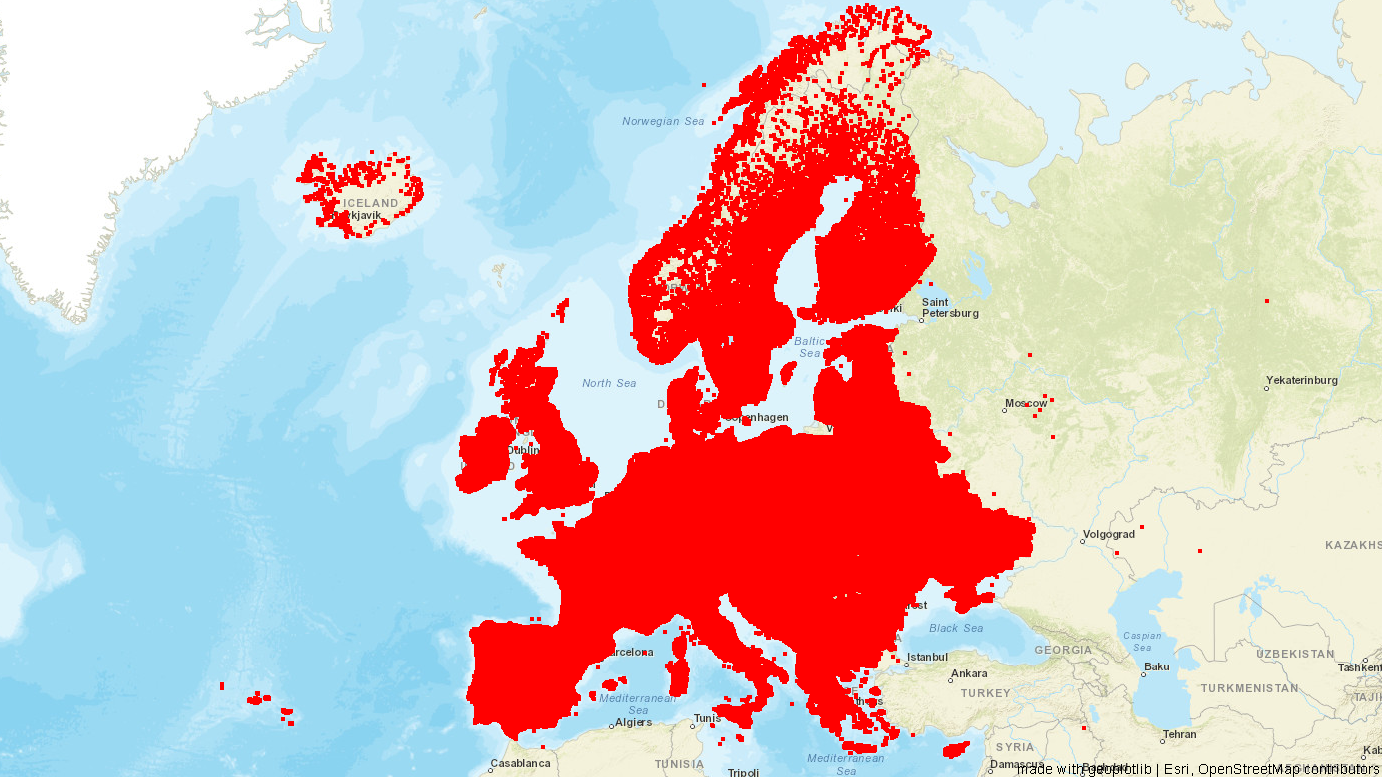

In [3]:
use_street_tiles()
geoplotlib.set_bbox(EUROPE_BBOX)
geoplotlib.dot(europe)
geoplotlib.savefig('01_europe_dots')
display(Image('01_europe_dots.png'))


## Cities whose names start with Z


Cities starting with Z: 13218


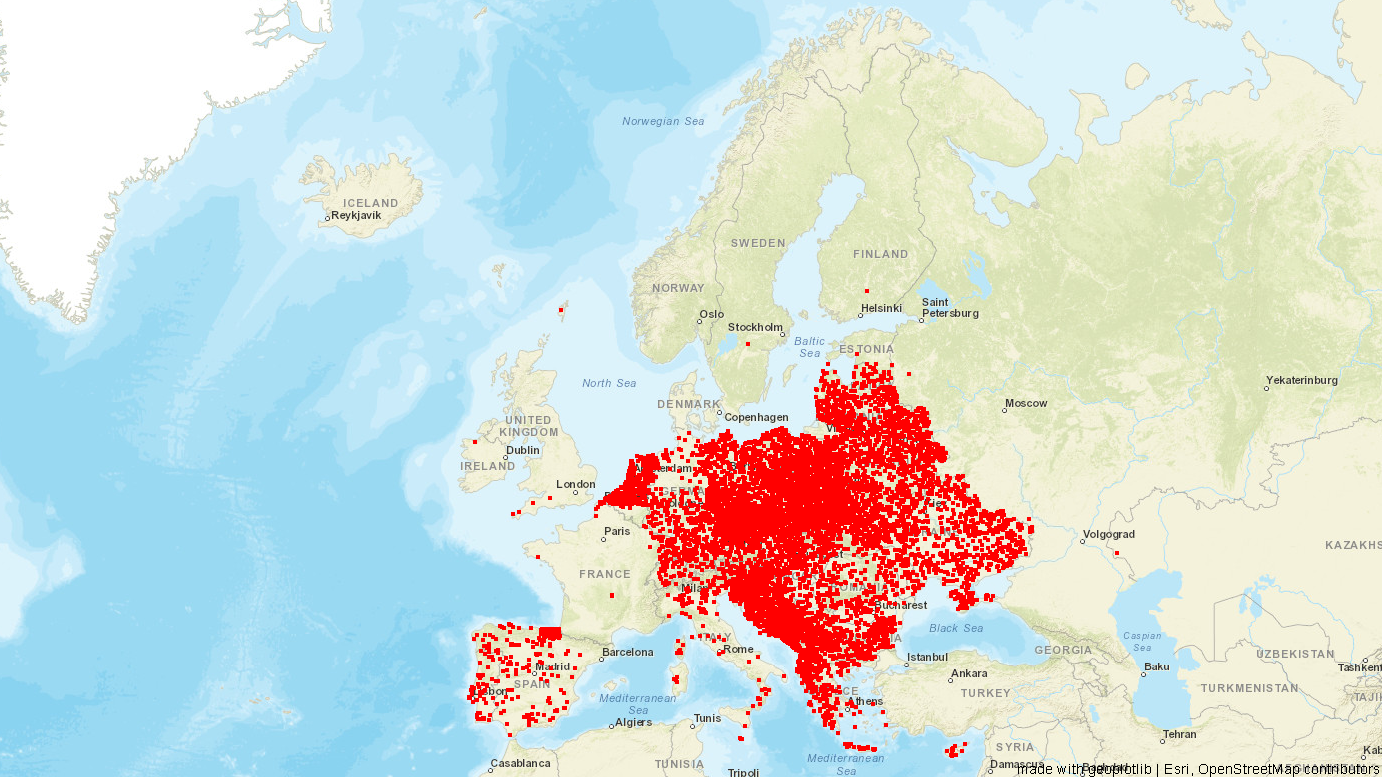

In [4]:
z_cities = europe[europe['city'].str.startswith('Z')].copy()
print("Cities starting with Z:", len(z_cities))
use_street_tiles()
geoplotlib.set_bbox(EUROPE_BBOX)
geoplotlib.dot(z_cities)
geoplotlib.savefig('02_letter_Z')
display(Image('02_letter_Z.png'))


## Interactive layer: the current letter is drawn in blue, with point size 2


In [5]:
class MyLayer(BaseLayer):
    def __init__(self, dataset, char='A'):
        self.data = dataset
        self.char = char
        self._bbox = EUROPE_BBOX

    def invalidate(self, proj):
        self.painter = BatchPainter()
        chosen = self.data[self.data['city'].str.startswith(self.char)]
        self.painter.set_color([0, 0, 255, 255])
        if len(chosen) == 0:
            return
        x, y = proj.lonlat_to_screen(chosen['lon'].to_numpy(), chosen['lat'].to_numpy())
        self.painter.points(x, y, point_size=2, rounded=False)

    def draw(self, proj, mouse_x, mouse_y, ui_manager):
        self.painter.batch_draw()
        ui_manager.info('Letter: %s' % self.char)

    def on_key_release(self, key, modifiers):
        if 97 <= key <= 122:
            self.char = chr(key).upper()
            return True
        return False

    def bbox(self):
        return self._bbox


## Saved views for A, B and C


A 25099
B 54669
C 38394


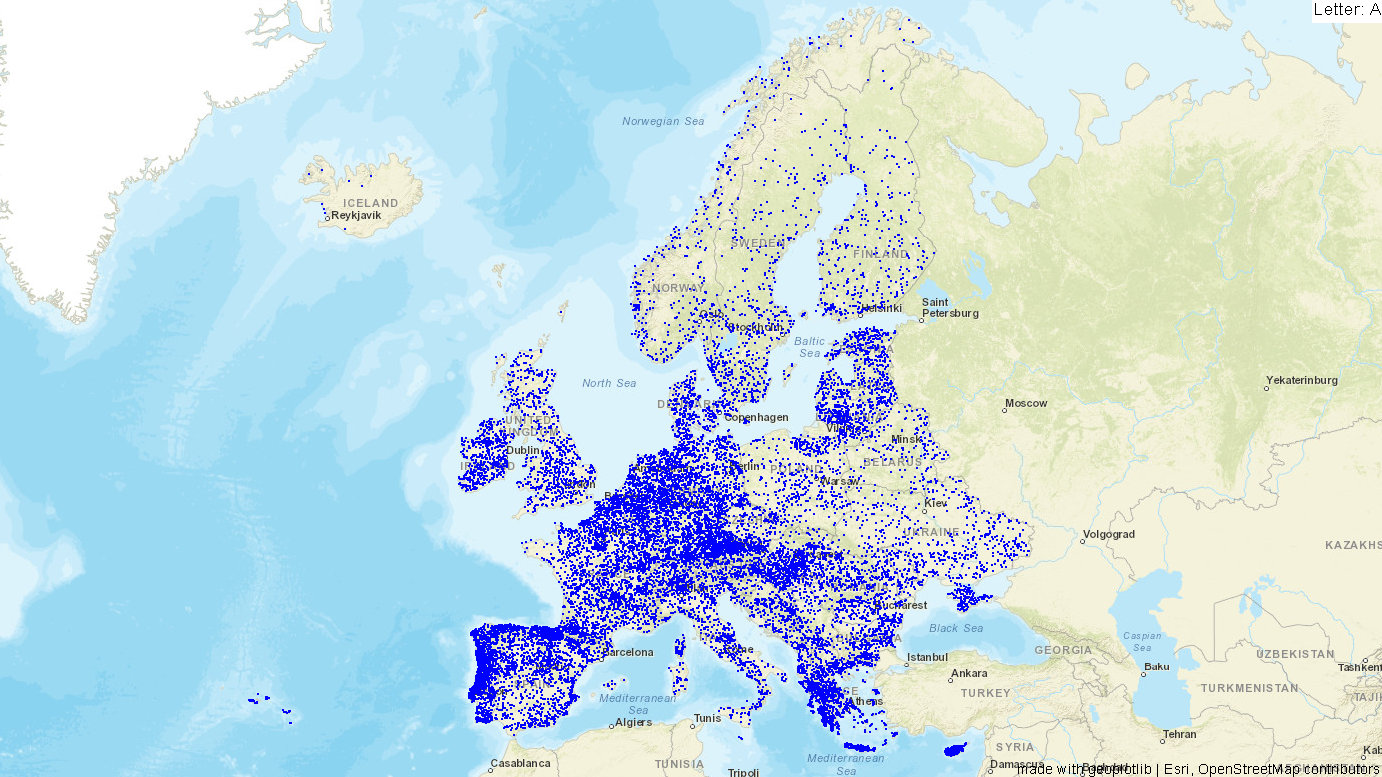

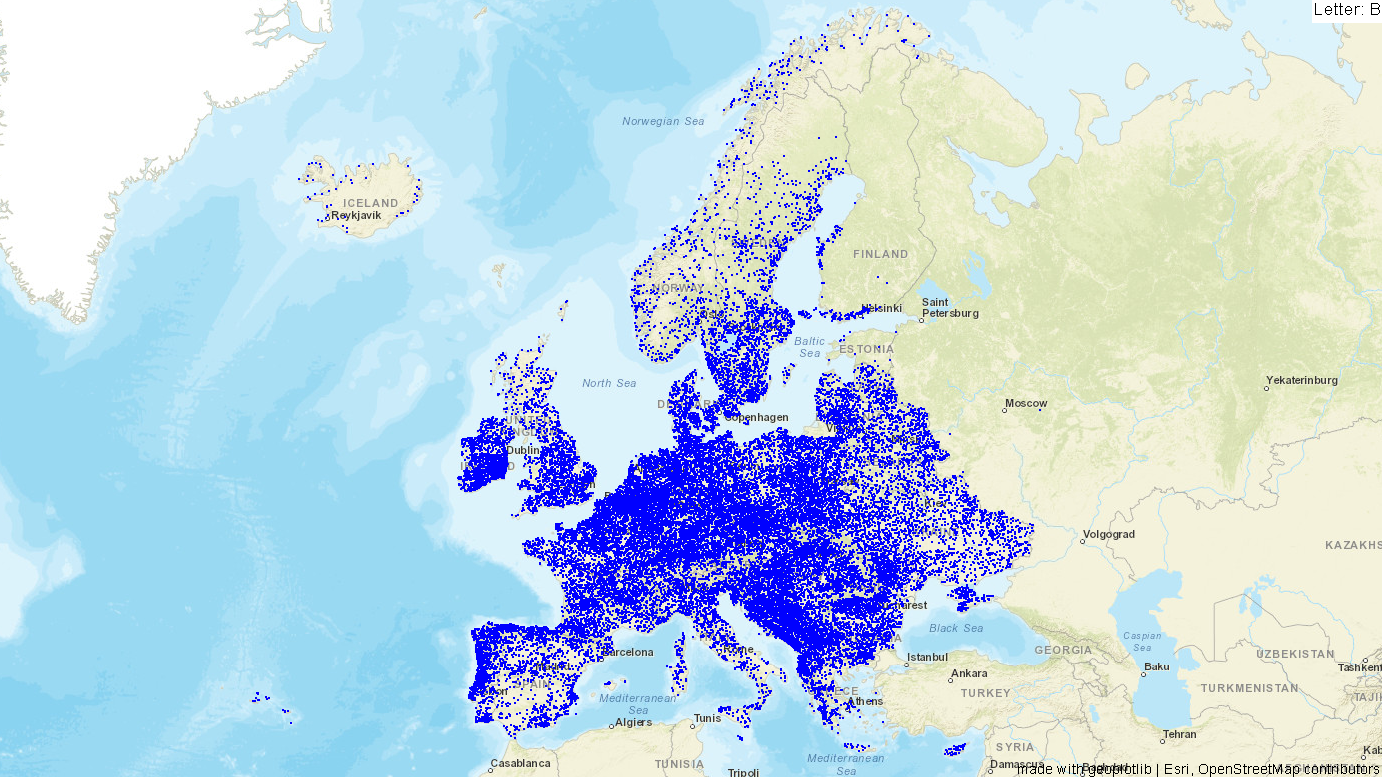

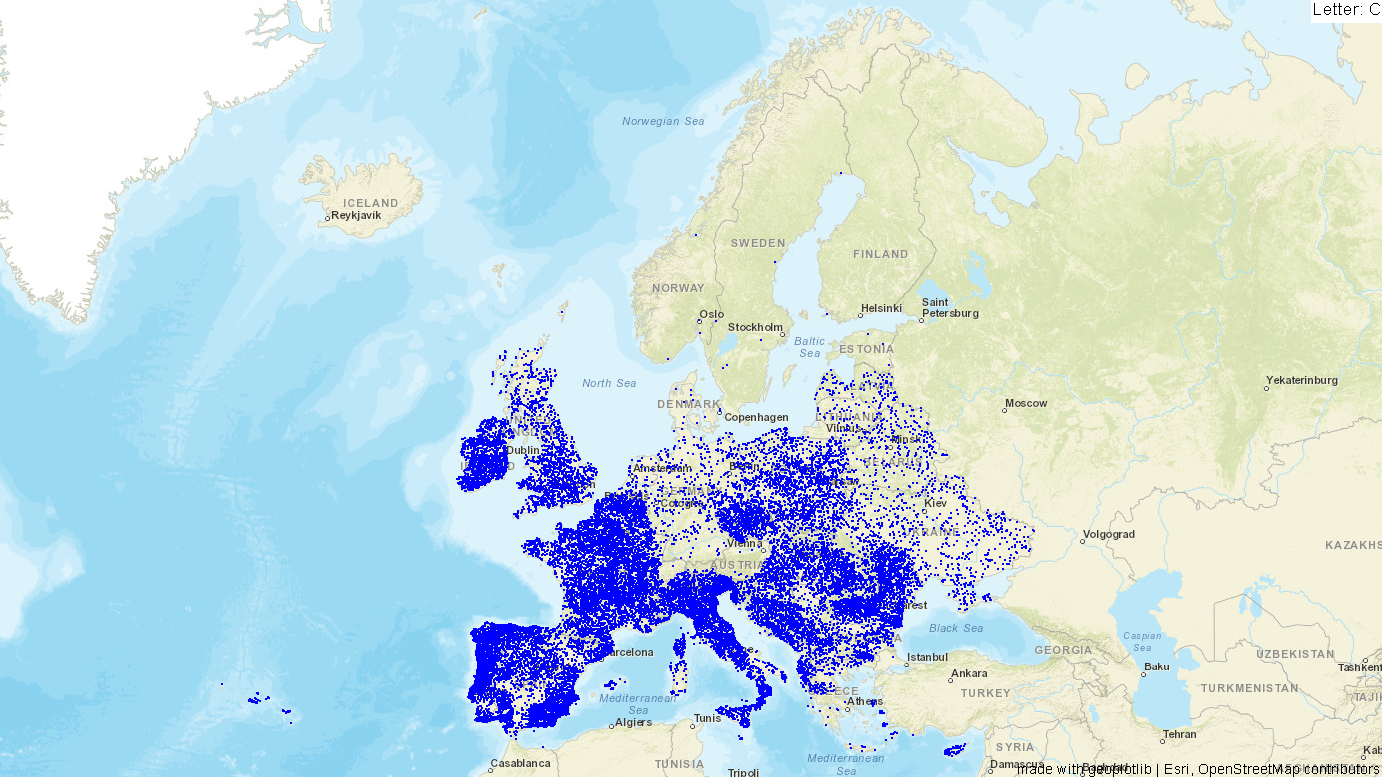

In [6]:
for letter in 'ABC':
    print(letter, int(europe['city'].str.startswith(letter).sum()))
    use_street_tiles()
    geoplotlib.set_bbox(EUROPE_BBOX)
    geoplotlib.add_layer(MyLayer(europe, char=letter))
    geoplotlib.savefig('03_letter_%s' % letter)
    display(Image('03_letter_%s.png' % letter))


## Observation

The full European set is a dense red cover of the continent. Names starting with Z are fewer and cluster in Central and Eastern Europe and Iberia. The custom layer starts at A and redraws when another letter is released. A, B and C are all common, so their blue patterns stay dense, with B the fullest of the three.
